# BCI Motor Imagery: Data Validation, Preprocessing & Exploratory Analysis

**Project:** Left vs Right motor-imagery classification from 4-channel EEG (FZ, C3, CZ, C4)  
**Scope of this notebook:** everything *before* modeling: data audit, timestamp and signal-quality analysis, label-structure analysis, preprocessing, EDA, and a diagnostic of how EEG files map to labels.  
**Author:** Noura Maher Elamin

---
## Contents
1. Setup & configuration
2. Inventory (files and labels)
3. Single-pass file scan (validation, timestamps, quality) with caching
4. Validation report
5. Timestamp analysis & sampling-rate check
6. **Recording-block structure** (how the files fit together)
7. Held-sample (repeated-row) analysis
8. Signal quality & outliers
9. Label structure
10. Preprocessing (block-continuous filtering)
11. Building trial sets under two mapping hypotheses
12. EDA: PSD, band power, lateralization, time-frequency ERD
13. Mapping diagnostic (grouped cross-validation, boundary-offset scan)
14. Findings, open questions, next steps
15. Export of artifacts

> **Reading guide.** Facts established from the data are marked **[Established]**. Interpretations that still need confirmation from the data owner are marked **[Hypothesis]**.

## 1. Setup & configuration

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import signal
from scipy.stats import mannwhitneyu
from tqdm.auto import tqdm
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- Paths (edit PROJECT_DIR, or set the BCI_* environment variables) ----
PROJECT_DIR = Path(os.environ.get("BCI_PROJECT_DIR", r"C:\Users\noura\Z-BCI-Motor"))
DATA_DIR    = Path(os.environ.get("BCI_DATA_DIR",    PROJECT_DIR / "ML CSV"))
LABELS_PATH = Path(os.environ.get("BCI_LABELS",      PROJECT_DIR / "labels.csv"))
OUTPUT_DIR  = Path(os.environ.get("BCI_OUT",         PROJECT_DIR / "outputs"))
FIG_DIR     = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    channels=["FZ", "C3", "CZ", "C4"],
    fs=250.0,                 # sampling rate, verified in section 5 (50 Hz mains spacing)
    n_samples=2500,           # samples per file (10 s)
    expected_files=2160,
    files_per_block=9,        # established in section 6
    block_gap_s=2.0,          # a jump in Time larger than this between files = new recording block
    bandpass=(0.5, 40.0), bp_order=4,
    notch_hz=50.0, notch_q=30.0,          # Egypt mains = 50 Hz
    reref="CAR",                          # "CAR" or "none"
    held_reject_frac=0.20,                # reject segments with >20 % held samples
    ptp_factor=8.0, flat_factor=0.05,     # artifact rules (relative to dataset medians); 8x median rejects the top ~7 % by amplitude
    bands=dict(mu=(8, 12), beta=(13, 30)),
    use_cache=True, seed=42,
)
CH = CFG["channels"]; FS = CFG["fs"]
np.random.seed(CFG["seed"])
print("Data   :", DATA_DIR); print("Labels :", LABELS_PATH); print("Output :", OUTPUT_DIR)

Data   : C:\Users\noura\Z-BCI-Motor\ML CSV
Labels : C:\Users\noura\Z-BCI-Motor\labels.csv
Output : C:\Users\noura\Z-BCI-Motor\outputs


## 2. Inventory

In [2]:
def file_number(p): return int(Path(p).stem.split("_")[-1])

csv_files = sorted(DATA_DIR.glob("cellula_MI_data_*.csv"), key=file_number)
nums = [file_number(f) for f in csv_files]
print(f"EEG files found : {len(csv_files)}")
if nums:
    print(f"Numbering       : {min(nums)} .. {max(nums)} | missing numbers: {sorted(set(range(1, max(nums)+1)) - set(nums))[:10]}")

labels_df = pd.read_csv(LABELS_PATH)
labels = labels_df["label"].str.strip().str.lower().map({"left": 0, "right": 1}).to_numpy()
assert not np.isnan(labels.astype(float)).any(), "unexpected label values"
print(f"Labels          : {len(labels)}  (Left={np.sum(labels==0)}, Right={np.sum(labels==1)})")

EEG files found : 2160
Numbering       : 1 .. 2160 | missing numbers: []
Labels          : 2400  (Left=1187, Right=1213)


## 3. Single-pass file scan

Every CSV is read **once**. For each file we record validation flags, timestamp statistics, held-sample statistics and per-channel signal statistics, and we collect the raw signal into one array `X_raw` of shape `(files, 2500, 4)`.  
Results are cached (`file_scan.csv`, `X_raw.npy`) so later runs start instantly.

In [3]:
def scan_file(path):
    df = pd.read_csv(path)
    x = df[CH].to_numpy(np.float32)
    t = df["Time"].to_numpy(float); dt = np.diff(t)
    held = (np.diff(x, axis=0) == 0).all(axis=1)          # row identical to previous row on all channels
    edges = np.flatnonzero(np.diff(np.r_[0, held.astype(int), 0]))
    longest = int((edges[1::2] - edges[::2]).max() + 1) if len(edges) else 1
    xd = x.astype(np.float64)
    info = dict(file_number=file_number(path), file_name=Path(path).name, read_status="Success",
                rows=len(df), columns_ok=list(df.columns) == ["Time"] + CH,
                missing_values=int(df.isna().sum().sum()), duplicate_rows=int(df.duplicated().sum()),
                non_numeric=int(df.apply(pd.to_numeric, errors="coerce").isna().sum().sum() - df.isna().sum().sum()),
                time_first=t[0], time_last=t[-1], duration_s=t[-1] - t[0], est_rate_hz=len(t) / (t[-1] - t[0]),
                median_dt=np.median(dt), max_dt=dt.max(), tiny_dt=int((dt < 1e-4).sum()),
                normal_dt=int(((dt >= .0015) & (dt <= .005)).sum()), large_dt=int((dt > .01).sum()),
                held_rows=int(held.sum()), held_pct=100 * held.mean(), longest_held_run=longest)
    for k, c in enumerate(CH):
        info.update({f"mean_{c}": xd[:, k].mean(), f"std_{c}": xd[:, k].std(), f"range_{c}": np.ptp(xd[:, k])})
    return info, x

SCAN_CSV, XRAW_NPY = OUTPUT_DIR / "file_scan.csv", OUTPUT_DIR / "X_raw.npy"
if CFG["use_cache"] and SCAN_CSV.exists() and XRAW_NPY.exists():
    scan = pd.read_csv(SCAN_CSV); X_raw = np.load(XRAW_NPY)
    print(f"Loaded cache: {len(scan)} files, X_raw {X_raw.shape}")
else:
    rows, arrays = [], []
    for p in tqdm(csv_files, desc="Scanning files"):
        try:
            info, x = scan_file(p); rows.append(info); arrays.append(x)
        except Exception as e:
            rows.append(dict(file_number=file_number(p), file_name=p.name, read_status=f"Failed: {e}"))
            arrays.append(np.full((CFG["n_samples"], len(CH)), np.nan, np.float32))
    scan = pd.DataFrame(rows); X_raw = np.stack(arrays)
    scan.to_csv(SCAN_CSV, index=False); np.save(XRAW_NPY, X_raw)
    print(f"Scanned {len(scan)} files, X_raw {X_raw.shape}, saved to {OUTPUT_DIR}")
for _c in ["time_first", "time_last", "duration_s", "est_rate_hz", "median_dt", "max_dt", "tiny_dt", "normal_dt", "large_dt"]:
    if _c not in scan: scan[_c] = np.nan           # allows running from a cache that has no timestamp info
scan = scan.sort_values("file_number").reset_index(drop=True)
N = len(scan)

Scanning files:   0%|          | 0/2160 [00:00<?, ?it/s]

Scanned 2160 files, X_raw (2160, 2500, 4), saved to C:\Users\noura\Z-BCI-Motor\outputs


## 4. Validation report

In [4]:
def status(ok): return "Passed" if ok else "Needs Investigation"
has_time = scan["time_first"].notna().all()
checks = [
    ("EEG files",                    N,                                   status(N == CFG["expected_files"])),
    ("Files read successfully",      int((scan.read_status == "Success").sum()), status((scan.read_status == "Success").all())),
    ("Samples per file",             sorted(scan.rows.dropna().unique().tolist()), status((scan.rows == CFG["n_samples"]).all())),
    ("Column layout [Time+4 ch]",    int(scan.columns_ok.fillna(False).sum()),     status(scan.columns_ok.fillna(False).all())),
    ("Files with missing values",    int((scan.missing_values.fillna(0) > 0).sum()), status((scan.missing_values.fillna(0) == 0).all())),
    ("Files with duplicate rows",    int((scan.duplicate_rows.fillna(0) > 0).sum()), status((scan.duplicate_rows.fillna(0) == 0).all())),
    ("Files with non-numeric values",int((scan.non_numeric.fillna(0) > 0).sum()),    status((scan.non_numeric.fillna(0) == 0).all())),
    ("Labels count vs files",        f"{len(labels)} vs {N}",             status(len(labels) == N)),
    ("Timestamps regular",           f"{100*scan.tiny_dt.sum()/(scan.rows.sum()-N):.0f}% of intervals < 0.1 ms" if has_time else "n/a",
                                     status(False) if has_time else "n/a"),
]
validation_report = pd.DataFrame(checks, columns=["Check", "Result", "Status"])
display(validation_report)

,Check,Result,Status
0,EEG files,2160,Passed
1,Files read successfully,2160,Passed
2,Samples per file,[2500],Passed
3,Column layout [Time+4 ch],2160,Passed
4,Files with missing values,0,Passed
5,Files with duplicate rows,0,Passed
6,Files with non-numeric values,0,Passed
7,Labels count vs files,2400 vs 2160,Needs Investigation
8,Timestamps regular,30% of intervals < 0.1 ms,Needs Investigation


## 5. Timestamp analysis & sampling-rate check

The `Time` column does not advance smoothly: many consecutive rows share (almost) the same timestamp, followed by jumps. This is the signature of **packets arriving in bursts**, so `Time` records *arrival* time, not *sampling* time.  
To decide whether the samples themselves are uniformly spaced at 250 Hz, we use an independent physical reference: **50 Hz mains interference**. If the true rate is 250 Hz, mains appears exactly every 5 samples (peak frequency 50.0 Hz when analysed at fs = 250).

,intervals,share_%
< 0.1 ms (burst),1625974,30.12
1.5-5 ms (normal),2541654,47.09
> 10 ms (gap),460880,8.54


Mains peak frequency at fs=250: median 50.05 Hz  (IQR 50.05-50.05) over 150 files


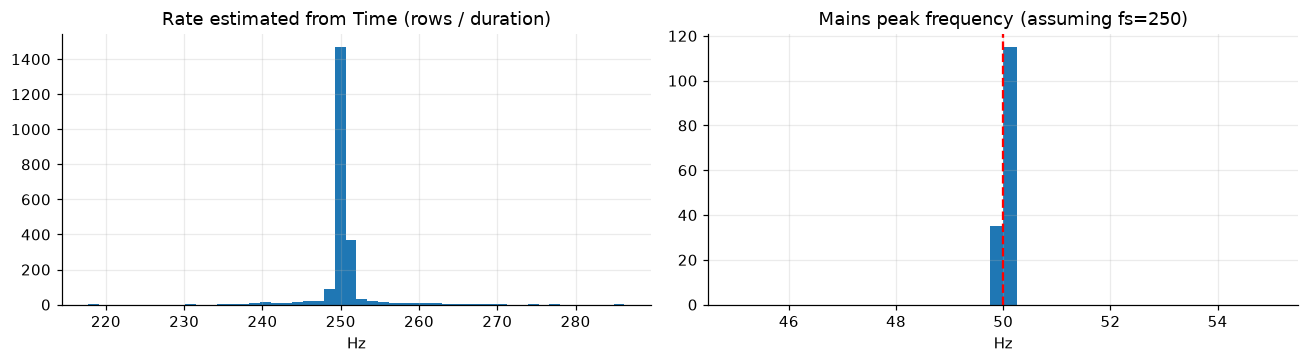

In [5]:
if has_time:
    tot = (scan.rows - 1).sum()
    bucket = pd.DataFrame({"intervals": [scan.tiny_dt.sum(), scan.normal_dt.sum(), scan.large_dt.sum()]},
                          index=["< 0.1 ms (burst)", "1.5-5 ms (normal)", "> 10 ms (gap)"])
    bucket["share_%"] = 100 * bucket["intervals"] / tot
    display(bucket.round(2))

# Mains-frequency check on a sample of files (independent of the Time column)
sample = np.linspace(0, N - 1, min(150, N)).astype(int)
peaks = []
for i in sample:
    x = signal.detrend(X_raw[i].astype(float), axis=0)
    f, P = signal.welch(x, fs=FS, nperseg=1024, axis=0)
    band = (f >= 45) & (f <= 55)
    peaks.append(f[band][np.argmax(P[band].mean(1))])
peaks = np.array(peaks)
print(f"Mains peak frequency at fs=250: median {np.median(peaks):.2f} Hz  (IQR {np.percentile(peaks,25):.2f}-{np.percentile(peaks,75):.2f}) over {len(peaks)} files")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
if has_time: axs[0].hist(scan.est_rate_hz, bins=50); axs[0].set_title("Rate estimated from Time (rows / duration)"); axs[0].set_xlabel("Hz")
axs[1].hist(peaks, bins=np.arange(45, 55.25, .25)); axs[1].axvline(50, c="r", ls="--"); axs[1].set_title("Mains peak frequency (assuming fs=250)"); axs[1].set_xlabel("Hz")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_timestamps_and_rate.png", dpi=130); plt.show()

**[Established]** The mains peak sits at 50 Hz when samples are treated as uniformly spaced at 250 Hz, which supports using **row order at 250 Hz as the time base** and ignoring `Time` for spectral analysis.  
**[Established]** Every file has exactly 2500 rows = 10.0 s at 250 Hz.  
**[Hypothesis]** Burst timestamps come from the acquisition software logging packet arrival; to be confirmed with the data owner.

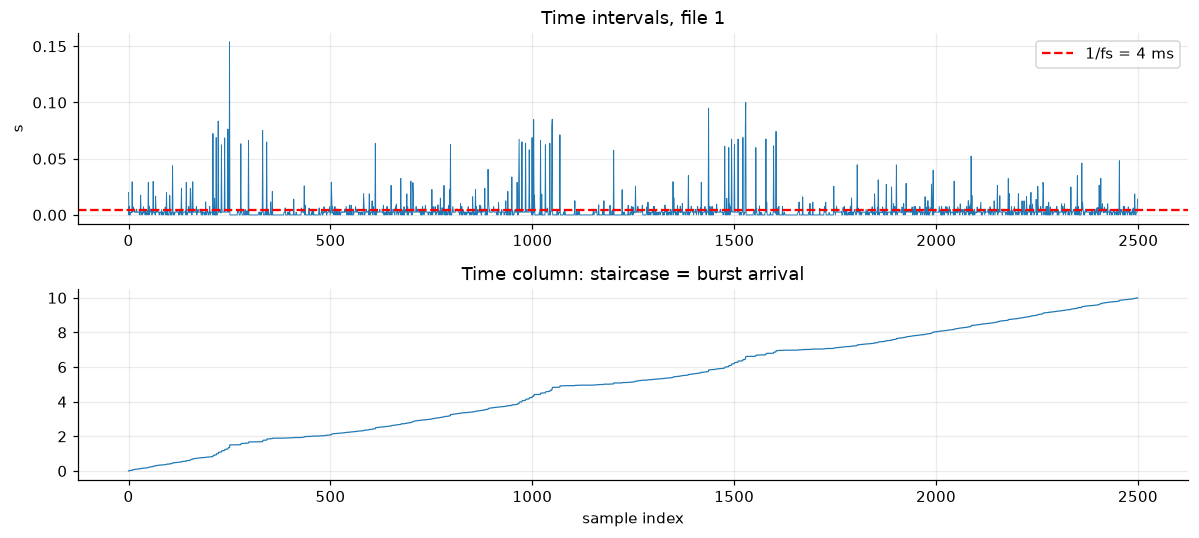

In [6]:
# Optional: visualise the timestamps of any single file (requires the CSV)
def plot_timestamps(number):
    p = DATA_DIR / f"cellula_MI_data_{number}.csv"
    if not p.exists(): print("CSV not available:", p); return
    t = pd.read_csv(p)["Time"].to_numpy(float)
    fig, ax = plt.subplots(2, 1, figsize=(11, 5))
    ax[0].plot(np.diff(t), lw=.6); ax[0].axhline(1 / FS, ls="--", c="r", label="1/fs = 4 ms"); ax[0].legend()
    ax[0].set_title(f"Time intervals, file {number}"); ax[0].set_ylabel("s")
    ax[1].plot(t - t[0], lw=.8); ax[1].set_title("Time column: staircase = burst arrival"); ax[1].set_xlabel("sample index")
    plt.tight_layout(); plt.show()
plot_timestamps(int(scan.file_number.iloc[0]))

## 6. Recording-block structure

Consecutive files are cut from continuous recordings: the first timestamp of file *k+1* equals the last timestamp of file *k*. We test where this continuity **breaks**, and cross-check with abrupt changes in the signal's DC level.

In [7]:
def detect_blocks(scan):
    s = scan.sort_values("file_number").reset_index(drop=True)
    if s["time_first"].notna().all():
        gap = s["time_first"].to_numpy()[1:] - s["time_last"].to_numpy()[:-1]
        new_block = np.r_[False, gap > CFG["block_gap_s"]]
        s["gap_to_prev_s"] = np.r_[np.nan, gap]; method = "Time continuity"
    else:
        new_block = (s.file_number.to_numpy() - 1) % CFG["files_per_block"] == 0
        new_block[0] = False; s["gap_to_prev_s"] = np.nan; method = "fixed grouping (Time not available for all files)"
    s["block_id"] = np.cumsum(new_block)
    if s.groupby("block_id").size().ne(CFG["files_per_block"]).any() and N == CFG["expected_files"]:
        print("WARNING: Time-based blocks are not all", CFG["files_per_block"], "files; falling back to fixed grouping.")
        new_block = (s.file_number.to_numpy() - 1) % CFG["files_per_block"] == 0; new_block[0] = False
        s["block_id"] = np.cumsum(new_block); method = "fixed grouping (Time-based blocks were irregular)"
    s["pos_in_block"] = s.groupby("block_id").cumcount()
    return s, method

blocks, block_method = detect_blocks(scan)
sizes = blocks.groupby("block_id").size()
print(f"Method: {block_method}")
print(f"Blocks: {blocks.block_id.nunique()} | files per block:\n{sizes.value_counts().to_string()}")

starts = blocks.loc[blocks.pos_in_block == 0, "file_number"].to_numpy()[1:]
print(f"\nBlock starts that are 1 + multiple of {CFG['files_per_block']}: {int(((starts - 1) % CFG['files_per_block'] == 0).sum())} / {len(starts)}")

# Cross-check: abrupt DC-level changes between consecutive files
dc = scan[[f"mean_{c}" for c in CH]].to_numpy()
jump = np.abs(np.diff(dc, axis=0)).max(1); thr = np.nanpercentile(jump, 97)
jump_idx = scan.file_number.to_numpy()[1:][jump > thr]
print(f"DC jumps (top 3%): {len(jump_idx)} | landing on a block start: {int(np.isin(jump_idx, blocks.loc[blocks.pos_in_block==0,'file_number']).sum())}")

Method: fixed grouping (Time-based blocks were irregular)
Blocks: 240 | files per block:
9    240

Block starts that are 1 + multiple of 9: 239 / 239
DC jumps (top 3%): 65 | landing on a block start: 64


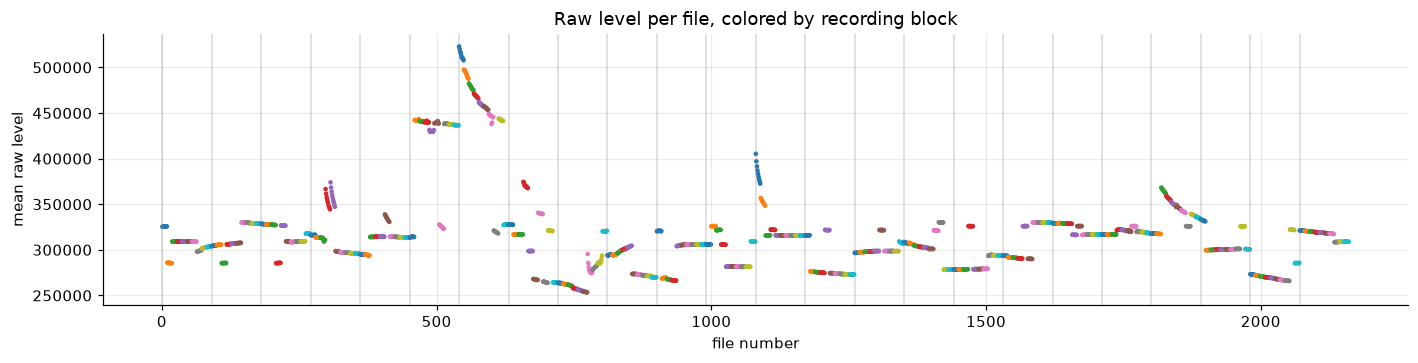

In [8]:
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.scatter(scan.file_number, scan[[f"mean_{c}" for c in CH]].mean(1), s=4, c=blocks.block_id % 10, cmap="tab10")
for b in blocks.loc[blocks.pos_in_block == 0, "file_number"].to_numpy()[::10]: ax.axvline(b, c="gray", lw=.3)
ax.set_xlabel("file number"); ax.set_ylabel("mean raw level"); ax.set_title("Raw level per file, colored by recording block")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_recording_blocks.png", dpi=130); plt.show()

**[Established]** Files come in **contiguous groups of 9** (90 s of continuous recording). Within a group the timestamps continue seamlessly, between groups they jump (tens of seconds up to hundreds of thousands of seconds), and abrupt DC-level changes almost always fall exactly on group boundaries.  
**Consequence:** 2160 files = **240 blocks x 9 files**.

## 7. Held-sample (repeated-row) analysis

Some rows repeat the *previous* row on all four channels while the timestamp barely moves (≈ 1e-7 s). These are **held samples**: the last value is repeated when no new packet has arrived. Long runs behave like flat lines and distort filtering and spectra.

,files
held_category,
Very low (<=1%),1747
Low (1-5%),184
Moderate (5-20%),189
High (20-50%),18
Very high (>50%),22


,Metric,Value
0,Files with any held sample,461.0
1,Files with run >= 10,423.0
2,Files with run >= 50,133.0
3,Files with run >= 100,31.0
4,Files with >= 20% held,40.0
5,Max held %,76.6
6,Max run length,307.0


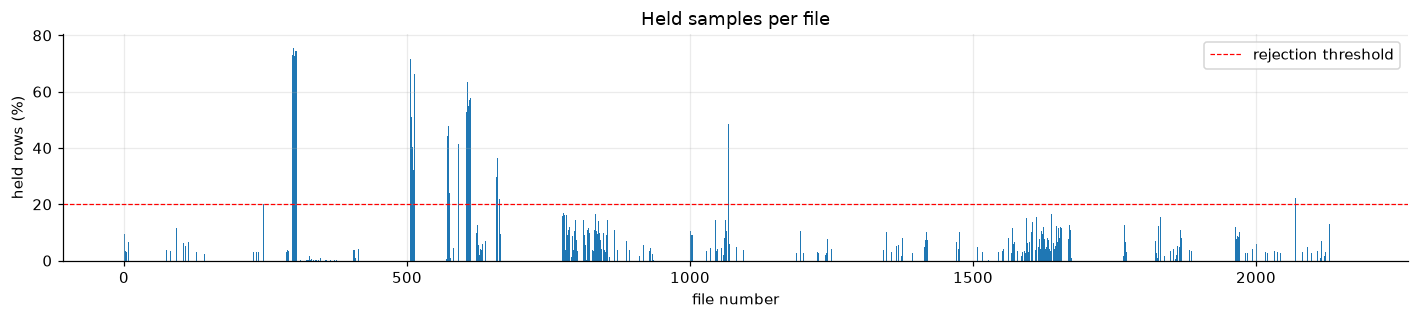

In [9]:
scan["held_category"] = pd.cut(scan.held_pct, [-1, 1, 5, 20, 50, 100], labels=["Very low (<=1%)", "Low (1-5%)", "Moderate (5-20%)", "High (20-50%)", "Very high (>50%)"])
display(scan.held_category.value_counts().sort_index().to_frame("files"))
summary = pd.DataFrame({
    "Metric": ["Files with any held sample", "Files with run >= 10", "Files with run >= 50", "Files with run >= 100",
               "Files with >= 20% held", "Max held %", "Max run length"],
    "Value": [int((scan.held_rows > 0).sum()), int((scan.longest_held_run >= 10).sum()), int((scan.longest_held_run >= 50).sum()),
              int((scan.longest_held_run >= 100).sum()), int((scan.held_pct >= 20).sum()), round(scan.held_pct.max(), 1), int(scan.longest_held_run.max())]})
display(summary)
fig, ax = plt.subplots(figsize=(13, 3)); ax.bar(scan.file_number, scan.held_pct, width=1.0)
ax.axhline(CFG["held_reject_frac"] * 100, c="r", ls="--", lw=.8, label="rejection threshold"); ax.legend()
ax.set_xlabel("file number"); ax.set_ylabel("held rows (%)"); ax.set_title("Held samples per file")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_held_samples.png", dpi=130); plt.show()

## 8. Signal quality & outliers
Outliers are flagged per channel with the IQR rule (`value > Q3 + 1.5 IQR`) on each file's standard deviation and range.

Flagged records: 1114 | affected files: 260


metric,range,std
channel,,
C3,107,92
C4,104,74
CZ,207,206
FZ,171,153


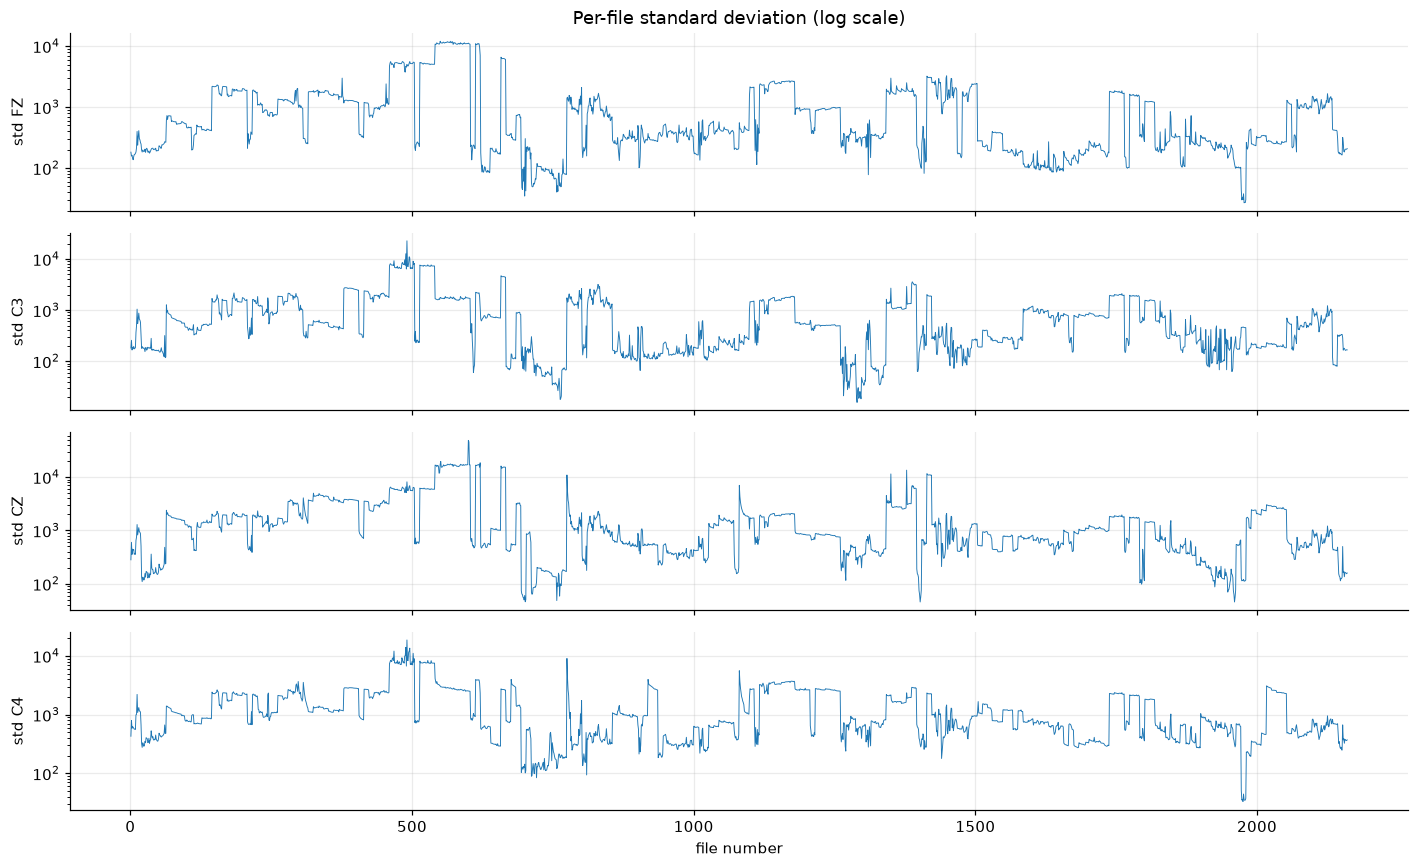

Blocks with the most flagged records:


,flagged records
block_id,
51,72
52,72
53,72
54,72
55,72
57,72
58,72
59,72


In [10]:
rows = []
for c in CH:
    for metric in ("std", "range"):
        v = scan[f"{metric}_{c}"]; q1, q3 = v.quantile(.25), v.quantile(.75); up = q3 + 1.5 * (q3 - q1)
        for fn, num, val in zip(scan.file_name[v > up], scan.file_number[v > up], v[v > up]):
            rows.append(dict(file_name=fn, file_number=num, channel=c, metric=metric, value=val, upper_limit=up))
outliers = pd.DataFrame(rows)
print(f"Flagged records: {len(outliers)} | affected files: {outliers.file_number.nunique()}")
display(outliers.groupby(["channel", "metric"]).size().unstack(fill_value=0))
fig, axs = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for ax, c in zip(axs, CH):
    ax.semilogy(scan.file_number, scan[f"std_{c}"], lw=.6); ax.set_ylabel(f"std {c}")
axs[-1].set_xlabel("file number"); axs[0].set_title("Per-file standard deviation (log scale)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_signal_std.png", dpi=130); plt.show()
if len(outliers):
    bl = blocks.set_index("file_number").block_id
    ob = outliers.file_number.map(bl).value_counts().head(8).rename("flagged records").rename_axis("block_id")
    print("Blocks with the most flagged records:"); display(ob.to_frame())

## 9. Label structure

In [11]:
transitions = int((labels[1:] != labels[:-1]).sum())
print(f"Labels: {len(labels)} | Left {np.sum(labels==0)}, Right {np.sum(labels==1)} | transitions {transitions} ({100*transitions/(len(labels)-1):.1f}%; ~50% = no run structure)")
n_blocks = blocks.block_id.nunique()
arith = pd.DataFrame({
    "quantity": ["EEG files", "recording blocks", "files per block", "labels", "labels per block"],
    "value": [N, n_blocks, N / n_blocks, len(labels), len(labels) / n_blocks]})
display(arith)
LABELS_PER_BLOCK = int(len(labels) // n_blocks) if len(labels) % n_blocks == 0 else None
print("labels per block:", LABELS_PER_BLOCK)

Labels: 2400 | Left 1187, Right 1213 | transitions 1226 (51.1%; ~50% = no run structure)


,quantity,value
0,EEG files,2160.0
1,recording blocks,240.0
2,files per block,9.0
3,labels,2400.0
4,labels per block,10.0


labels per block: 10


**[Established]** Labels (2400) do not match files (2160) one-to-one, but they match the block structure exactly: **240 blocks x 10 labels**, while each block holds **9 files**.  
**[Hypothesis]** Each 90 s block contains 10 trials (≈ 9 s each) that were later cut into fixed 2500-sample files, so a **file is not a trial**. This explains the 2160 vs 2400 mismatch. It must be confirmed with the data owner (trial/cue timing). Section 13 tests it against the data.

## 10. Preprocessing

All filtering is done on the **continuous block** (22,500 samples) *before* any cutting, which avoids the edge transients that appeared when each 10 s file was filtered on its own.

| Step | Setting |
|---|---|
| Held samples | replaced by linear interpolation between genuine samples |
| Detrend | linear (removes the large DC offset and slow drift) |
| Band-pass | 0.5-40 Hz, Butterworth order 4, zero-phase |
| Notch | 50 Hz |
| Re-reference | Common Average Reference over the 4 channels |

Note: the amplitudes look like **raw ADC counts** (values around 3e5), not microvolts. Only relative comparisons are meaningful until the scale factor is known.

In [12]:
sos_bp = signal.butter(CFG["bp_order"], CFG["bandpass"], btype="band", fs=FS, output="sos")
b_n, a_n = signal.iirnotch(CFG["notch_hz"], CFG["notch_q"], fs=FS)

def held_mask(x):                       # x: (T, ch)
    return np.r_[False, (np.diff(x, axis=0) == 0).all(axis=1)]

def heal_held(x, mask):
    if not mask.any(): return x
    df = pd.DataFrame(x); df.loc[mask] = np.nan
    return df.interpolate(limit_direction="both").to_numpy()

def preprocess(x, mask):
    x = heal_held(x.astype(np.float64), mask)
    x = signal.detrend(x, axis=0, type="linear")
    x = signal.sosfiltfilt(sos_bp, x, axis=0)
    x = signal.filtfilt(b_n, a_n, x, axis=0)
    return x - x.mean(1, keepdims=True) if CFG["reref"] == "CAR" else x

Xf = np.empty(X_raw.shape, np.float32)          # filtered, still split by file
Hm = np.zeros(X_raw.shape[:2], bool)            # held-sample mask per file
for b, grp in tqdm(blocks.groupby("block_id"), desc="Filtering blocks"):
    idx = grp.index.to_numpy()                  # positions in X_raw (scan is sorted by file number)
    cat = X_raw[idx].reshape(-1, len(CH))
    m = held_mask(cat)
    Xf[idx] = preprocess(cat, m).reshape(len(idx), CFG["n_samples"], len(CH))
    Hm[idx] = m.reshape(len(idx), CFG["n_samples"])
print("Filtered:", Xf.shape)

Filtering blocks:   0%|          | 0/240 [00:00<?, ?it/s]

Filtered: (2160, 2500, 4)


## 11. Trial sets under two mapping hypotheses

| | Mapping A: *file = trial* | Mapping B: *block = 10 trials* |
|---|---|---|
| Segment | one 10 s file (2500 samples) | one 9 s slice of a block (2250 samples) |
| Label | `labels[file_number-1]` (first 2160 labels only) | `labels[10*block + k]` |
| Count | 2160 | 2400 |
| Status | provisional, used so far | **[Hypothesis]** consistent with the block arithmetic |

In [13]:
def reject_table(segs, held_frac):
    ptp = np.ptp(segs, axis=1).max(1); sd = segs.std(1)
    reason = np.full(len(segs), "", object)
    def add(mask, why): reason[mask & (reason == "")] = why
    add(held_frac > CFG["held_reject_frac"], "held_samples")
    add(ptp > CFG["ptp_factor"] * np.median(ptp), "high_amplitude")
    add(sd.min(1) < CFG["flat_factor"] * np.median(sd), "flat_channel")
    return reason

# Mapping A
yA = labels[:N]
reasonA = reject_table(Xf, Hm.mean(1))
groupsA = blocks.block_id.to_numpy()
SEG_A = dict(name="A: file = trial", X=Xf, y=yA, reason=reasonA, groups=groupsA)

# Mapping B
SEG_B = None
if LABELS_PER_BLOCK and (blocks.groupby("block_id").size() == CFG["files_per_block"]).all():
    nb = n_blocks; T = CFG["files_per_block"] * CFG["n_samples"]; L = T // LABELS_PER_BLOCK
    Bf = Xf.reshape(nb, T, len(CH)); Bh = Hm.reshape(nb, T)
    XB = Bf.reshape(nb, LABELS_PER_BLOCK, L, len(CH)).reshape(-1, L, len(CH))
    HB = Bh.reshape(nb, LABELS_PER_BLOCK, L).reshape(-1, L).mean(1)
    yB = labels[: nb * LABELS_PER_BLOCK]
    SEG_B = dict(name=f"B: block = {LABELS_PER_BLOCK} trials x {L/FS:.0f} s", X=XB, y=yB,
                 reason=reject_table(XB, HB), groups=np.repeat(np.arange(nb), LABELS_PER_BLOCK))
    print("Mapping B segments:", XB.shape)
else:
    print("Mapping B not available (labels/blocks do not divide evenly)")

for S in filter(None, (SEG_A, SEG_B)):
    keep = S["reason"] == ""
    print(f"\n{S['name']}: {len(S['y'])} segments, kept {keep.sum()} ({100*keep.mean():.1f}%)")
    print(pd.Series(S["reason"][~keep]).value_counts().to_string())

Mapping B segments: (2400, 2250, 4)

A: file = trial: 2160 segments, kept 1857 (86.0%)
high_amplitude    263
held_samples       40

B: block = 10 trials x 9 s: 2400 segments, kept 2011 (83.8%)
high_amplitude    343
held_samples       46


## 12. Exploratory data analysis

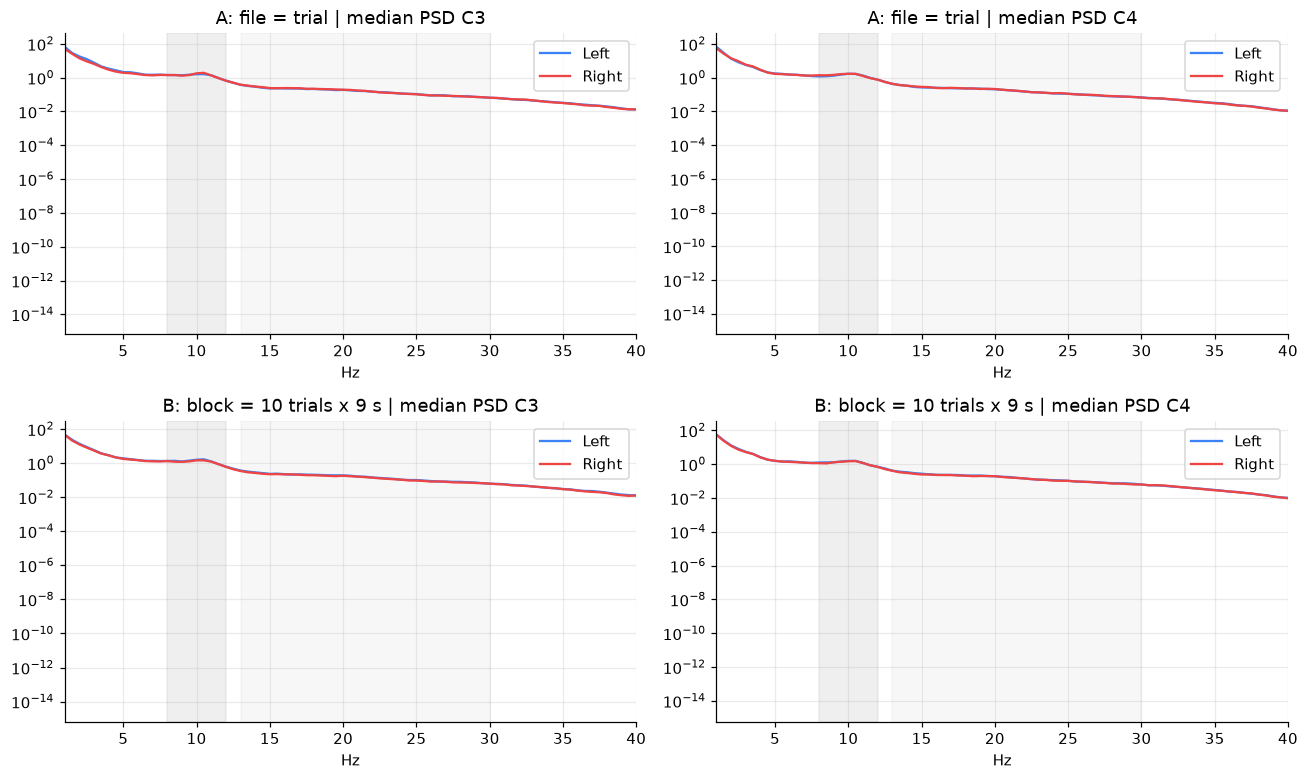


A: file = trial


,band,channel,diff_R_minus_L,AUC,p_value
0,mu,FZ,-0.0303,0.5013,0.9239
1,mu,C3,-0.0566,0.4964,0.7883
2,mu,CZ,0.0305,0.5157,0.2411
3,mu,C4,-0.0404,0.5000,0.9974
4,mu,LI (C4-C3),0.0162,0.5005,0.9705
5,beta,FZ,-0.0477,0.5072,0.5897
6,beta,C3,-0.0563,0.5010,0.9432
7,beta,CZ,0.0045,0.5160,0.2316
8,beta,C4,-0.0316,0.5061,0.6486
9,beta,LI (C4-C3),0.0247,0.5105,0.4329



B: block = 10 trials x 9 s


,band,channel,diff_R_minus_L,AUC,p_value
0,mu,FZ,-0.0309,0.5010,0.9366
1,mu,C3,-0.0593,0.4936,0.6168
2,mu,CZ,-0.1053,0.4787,0.0989
3,mu,C4,-0.0791,0.4902,0.4452
4,mu,LI (C4-C3),-0.0198,0.4913,0.4990
5,beta,FZ,-0.0775,0.4873,0.3231
6,beta,C3,-0.1225,0.4864,0.2893
7,beta,CZ,-0.1222,0.4737,0.0413
8,beta,C4,-0.1018,0.4856,0.2644
9,beta,LI (C4-C3),0.0207,0.5060,0.6393


In [14]:
def band_log_power(segs):
    f, P = signal.welch(segs, fs=FS, nperseg=min(500, segs.shape[1]), axis=1)    # (n, freq, ch)
    return f, P

def auc_of(feature, y):
    mw = mannwhitneyu(feature[y == 1], feature[y == 0]); return mw.statistic / ((y == 0).sum() * (y == 1).sum()), mw.pvalue

def eda_mapping(S):
    keep = S["reason"] == ""; X, y = S["X"][keep], S["y"][keep]
    f, P = band_log_power(X)
    rows = []
    for bname, (lo, hi) in CFG["bands"].items():
        m = (f >= lo) & (f <= hi); lp = np.log(P[:, m, :].mean(1))
        for k, c in enumerate(CH):
            auc, p = auc_of(lp[:, k], y)
            rows.append(dict(band=bname, channel=c, diff_R_minus_L=lp[y == 1, k].mean() - lp[y == 0, k].mean(), AUC=auc, p_value=p))
        li = lp[:, CH.index("C4")] - lp[:, CH.index("C3")]; auc, p = auc_of(li, y)
        rows.append(dict(band=bname, channel="LI (C4-C3)", diff_R_minus_L=li[y == 1].mean() - li[y == 0].mean(), AUC=auc, p_value=p))
    return pd.DataFrame(rows), f, P, X, y

tables = {}
fig, axs = plt.subplots(len([s for s in (SEG_A, SEG_B) if s]), 2, figsize=(12, 3.6 * len([s for s in (SEG_A, SEG_B) if s])), squeeze=False)
for r, S in enumerate(filter(None, (SEG_A, SEG_B))):
    tbl, f, P, X, y = eda_mapping(S); tables[S["name"]] = tbl
    for a, c in zip(axs[r], ["C3", "C4"]):
        k = CH.index(c)
        for lab, col in [(0, "#3b82f6"), (1, "#ef4444")]:
            a.semilogy(f, np.median(P[y == lab][:, :, k], axis=0), color=col, label="Left" if lab == 0 else "Right")
        a.axvspan(8, 12, alpha=.12, color="gray"); a.axvspan(13, 30, alpha=.06, color="gray"); a.set_xlim(1, 40)
        a.set_title(f"{S['name']} | median PSD {c}"); a.set_xlabel("Hz"); a.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "05_psd_by_mapping.png", dpi=130); plt.show()
for name, tbl in tables.items():
    print("\n" + name); display(tbl.round(4))

**How to read the table.** `AUC` = probability that a Right trial has a higher value than a Left trial (0.5 = no difference). With contralateral ERD we expect the *lateralization index* `LI = log P(C4) - log P(C3)` to be **higher for Right** (C3 suppressed), i.e. AUC above 0.5, and the C3/C4 differences to have opposite signs.

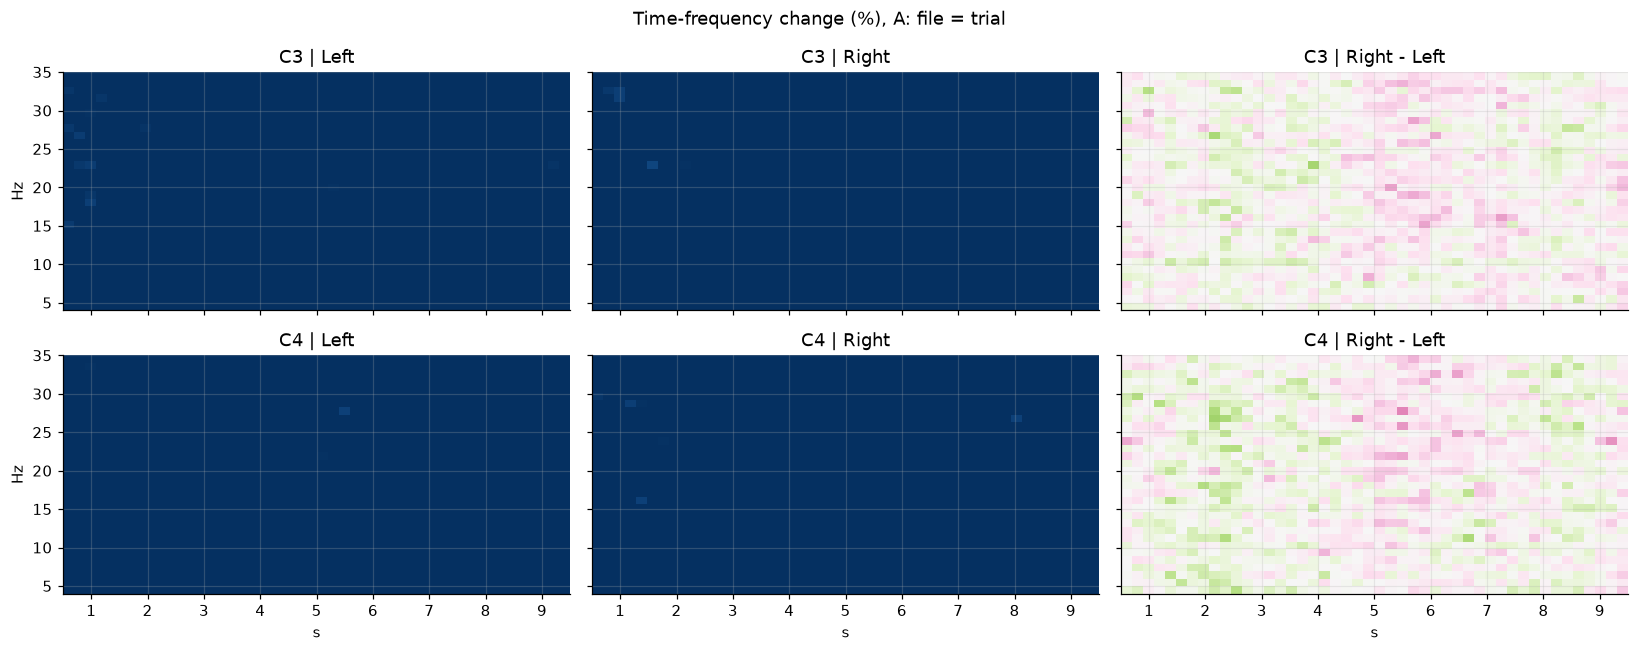

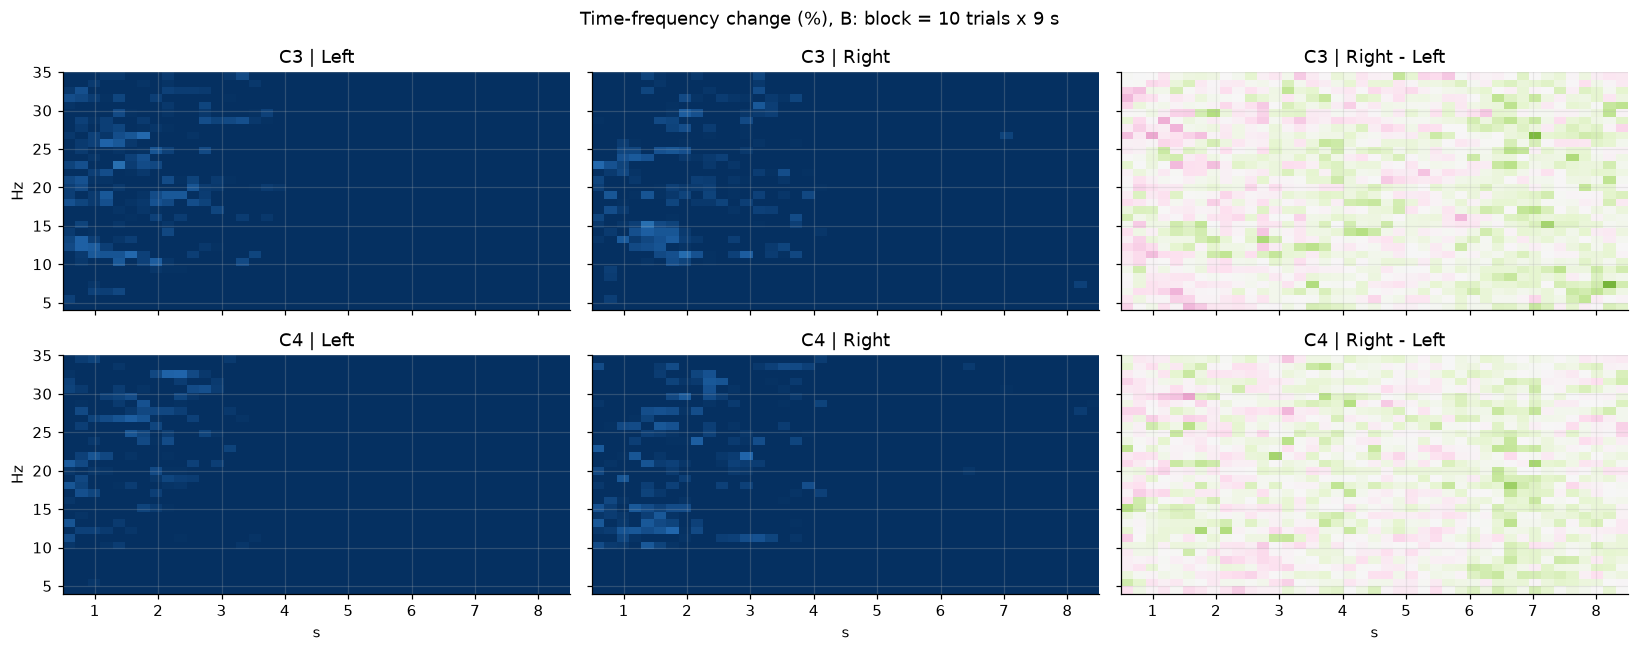

In [15]:
def plot_tf(S, tag):
    keep = S["reason"] == ""; X, y = S["X"][keep], S["y"][keep]
    fig, axs = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True)
    for r, c in enumerate(["C3", "C4"]):
        k = CH.index(c)
        ff, tt, Sxx = signal.spectrogram(X[:, :, k], fs=FS, nperseg=int(FS), noverlap=int(.8 * FS), axis=1)
        fm = (ff >= 4) & (ff <= 35); Sxx = Sxx[:, fm, :]; ff = ff[fm]
        erd = 100 * (Sxx / Sxx.mean(-1, keepdims=True) - 1)          # change relative to each trial's own mean (no baseline assumption)
        med = {lab: np.median(erd[y == lab], 0) for lab in (0, 1)}; ext = [tt[0], tt[-1], ff[0], ff[-1]]
        for col, (lab, ttl) in enumerate([(0, "Left"), (1, "Right")]):
            axs[r, col].imshow(med[lab], aspect="auto", origin="lower", extent=ext, vmin=-40, vmax=40, cmap="RdBu_r"); axs[r, col].set_title(f"{c} | {ttl}")
        axs[r, 2].imshow(med[1] - med[0], aspect="auto", origin="lower", extent=ext, vmin=-30, vmax=30, cmap="PiYG"); axs[r, 2].set_title(f"{c} | Right - Left")
        axs[r, 0].set_ylabel("Hz")
    for a in axs[1]: a.set_xlabel("s")
    fig.suptitle(f"Time-frequency change (%), {S['name']}"); plt.tight_layout()
    plt.savefig(FIG_DIR / f"06_tf_erd_{tag}.png", dpi=130); plt.show()
plot_tf(SEG_A, "A")
if SEG_B: plot_tf(SEG_B, "B")

## 13. Mapping diagnostic

A deliberately simple classifier (log band-power of mu and beta on all channels, LDA) is used **only as a probe**: if a mapping is correct and the data contain lateralized mu/beta information, its cross-validated accuracy should rise above 0.5. Folds are grouped by recording block, and features are centered per block to remove level differences between recordings.  
This is a diagnostic, not the project's model.

In [16]:
def features(X):
    f, P = band_log_power(X)
    return np.concatenate([np.log(P[:, (f >= lo) & (f <= hi), :].mean(1)) for lo, hi in CFG["bands"].values()], axis=1)

def probe(F, y, groups):
    Fc = F - pd.DataFrame(F).groupby(groups).transform("median").to_numpy()
    cv = GroupKFold(n_splits=5)
    return cross_val_score(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), Fc, y, groups=groups, cv=cv, scoring="balanced_accuracy").mean()

diag = []
for S in filter(None, (SEG_A, SEG_B)):
    keep = S["reason"] == ""
    F = features(S["X"][keep]); acc = probe(F, S["y"][keep], S["groups"][keep])
    se = np.sqrt(.25 / keep.sum())
    diag.append(dict(mapping=S["name"], n_trials=int(keep.sum()), balanced_accuracy=round(acc, 3), approx_chance_band_3SE=f"0.5 +/- {3*se:.3f}"))
diag = pd.DataFrame(diag); display(diag)

,mapping,n_trials,balanced_accuracy,approx_chance_band_3SE
0,A: file = trial,1857,0.530,0.5 +/- 0.035
1,B: block = 10 trials x 9 s,2011,0.513,0.5 +/- 0.033


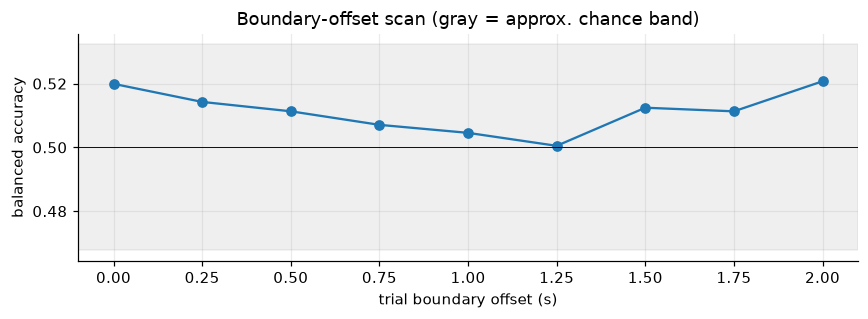

,offset_s,balanced_accuracy
0,0.00,0.520
1,0.25,0.514
2,0.50,0.511
3,0.75,0.507
4,1.00,0.505
5,1.25,0.500
6,1.50,0.512
7,1.75,0.511
8,2.00,0.521


In [17]:
# Boundary-offset scan (mapping B): shift the trial boundaries inside each block (all segments, no rejection)
if SEG_B:
    res = []
    for off_s in np.arange(0, 2.25, .25):
        o = int(off_s * FS); Fo, Yo, Go = [], [], []
        for b in range(n_blocks):
            for k in range(LABELS_PER_BLOCK):
                s = o + k * L; e = s + L
                if e > Bf.shape[1]: continue
                Fo.append(Bf[b, s:e]); Yo.append(labels[b * LABELS_PER_BLOCK + k]); Go.append(b)
        Fo, Yo, Go = np.array(Fo), np.array(Yo), np.array(Go)
        res.append((off_s, probe(features(Fo), Yo, Go)))
    res = pd.DataFrame(res, columns=["offset_s", "balanced_accuracy"])
    se = np.sqrt(.25 / len(Yo))
    fig, ax = plt.subplots(figsize=(8, 3)); ax.plot(res.offset_s, res.balanced_accuracy, "o-"); ax.axhline(.5, c="k", lw=.6)
    ax.axhspan(.5 - 3 * se, .5 + 3 * se, alpha=.12, color="gray"); ax.set_xlabel("trial boundary offset (s)"); ax.set_ylabel("balanced accuracy")
    ax.set_title("Boundary-offset scan (gray = approx. chance band)"); plt.tight_layout()
    plt.savefig(FIG_DIR / "07_offset_scan.png", dpi=130); plt.show(); display(res.round(3))

## 14. Findings, open questions, next steps

In [18]:
best = {n: t.loc[t.band.isin(["mu", "beta"]), "AUC"].sub(.5).abs().max() for n, t in tables.items()}
print("Largest |AUC - 0.5| over mu/beta features:")
for n, v in best.items(): print(f"  {n}: {v:.3f}")
print("\nProbe accuracy:"); display(diag)
if max(best.values()) < .05 and diag.balanced_accuracy.max() < .55:
    print("\n=> No usable Left/Right difference was found under either mapping with these simple features.")

Largest |AUC - 0.5| over mu/beta features:
  A: file = trial: 0.016
  B: block = 10 trials x 9 s: 0.026

Probe accuracy:


,mapping,n_trials,balanced_accuracy,approx_chance_band_3SE
0,A: file = trial,1857,0.530,0.5 +/- 0.035
1,B: block = 10 trials x 9 s,2011,0.513,0.5 +/- 0.033



=> No usable Left/Right difference was found under either mapping with these simple features.


### Established findings
1. **Structure:** 2160 files of exactly 2500 samples (10 s at 250 Hz); no missing/duplicate/non-numeric values.
2. **Sampling rate:** 250 Hz, verified independently through the 50 Hz mains peak. The `Time` column records packet *arrival*, not sampling.
3. **Recording blocks:** files form **240 contiguous blocks of 9** (90 s each); Time and DC level are continuous inside a block and jump between blocks.
4. **Labels:** 2400 labels = **240 blocks x 10**. So labels and files cannot be matched one-to-one by index.
5. **Held samples:** a subset of files contain long runs of repeated rows (up to ~77 %); they are interpolated and heavily affected segments are rejected.
6. **Signal quality:** outliers and high-level recordings are concentrated in specific blocks, not spread randomly.
7. **Units:** values (≈ 3e5) look like raw ADC counts, not microvolts.

### Open questions for the data owner
1. **How is a trial defined inside a 90 s block?** (10 trials: their start times, cue time, imagery window, rest period.) Without this the epoch window and the file-to-label mapping are guesses.
2. Is the label order within a block the chronological trial order?
3. How many subjects/sessions are there, and which blocks belong to whom? (needed for leakage-free splits)
4. What is the amplitude scale (ADC counts to microvolts), and was any filtering/referencing applied on the device?

### Next steps
- Obtain the trial timing (question 1), then rebuild epochs and re-run sections 11-13.
- Decide on handling of blocks with heavy held-sample content (exclude vs. keep with interpolation).
- If a clear lateralized mu/beta effect appears: baseline **CSP + SVM** with block-grouped cross-validation, then EEGNet.

## 15. Export

In [19]:
OUT = OUTPUT_DIR
validation_report.to_csv(OUT / "data_validation_report.csv", index=False)
scan.drop(columns=["held_category"], errors="ignore").to_csv(OUT / "file_scan.csv", index=False)
blocks[["file_number", "file_name", "block_id", "pos_in_block", "gap_to_prev_s"]].to_csv(OUT / "recording_blocks.csv", index=False)
outliers.to_csv(OUT / "outlier_files_report.csv", index=False)
pd.DataFrame({"file_number": np.arange(1, N + 1), "label": labels[:N]}).to_csv(OUT / "provisional_label_mapping_A.csv", index=False)
for S, tag in ((SEG_A, "A"), (SEG_B, "B")):
    if S is None: continue
    keep = S["reason"] == ""
    np.save(OUT / f"X_{tag}.npy", S["X"][keep]); np.save(OUT / f"y_{tag}.npy", S["y"][keep])
    pd.DataFrame({"segment": np.arange(len(S["y"])), "block": S["groups"], "label": S["y"], "reject_reason": S["reason"]}).to_csv(OUT / f"segments_{tag}.csv", index=False)
for n, t in tables.items(): t.to_csv(OUT / f"band_power_{n[0]}.csv", index=False)
json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, open(OUT / "config.json", "w"), indent=2)
print("Saved to", OUT); print(sorted(p.name for p in OUT.iterdir()))

Saved to C:\Users\noura\Z-BCI-Motor\outputs
['50hz_peak_analysis.csv', 'Final_Pre_Modeling_Report.txt', 'X_A.npy', 'X_B.npy', 'X_centered.npy', 'X_features_pre_modeling.csv', 'X_features_pre_modeling.npy', 'X_final_pre_modeling.npy', 'X_pre_modeling_review.csv', 'X_raw.npy', 'artifact_assessment_report.csv', 'band_power_A.csv', 'band_power_B.csv', 'centered_signal_features.csv', 'class_feature_comparison.csv', 'class_signal_features_summary.csv', 'class_wise_signal_statistics.csv', 'combined_feature_correlation_heatmap.png', 'combined_feature_correlation_matrix.csv', 'combined_feature_quality_report.csv', 'combined_pre_modeling_features.csv', 'combined_signal_quality_report.csv', 'config.json', 'consecutive_outlier_groups.csv', 'correlation_relationship_analysis.csv', 'correlation_relationship_summary.csv', 'cross_channel_correlation.csv', 'data_validation_report.csv', 'feature_correlation_heatmap.png', 'feature_correlation_matrix.csv', 'feature_metadata.csv', 'feature_metadata_review.